# Notebook 03: Generation Strategies, Plot-Twists & Human Evaluation
## DSL 504 — NLP Group Assignment 2 | Question 4: The Plot-Twist Generator

This comprehensive notebook covers **Part 3 (15 Marks)**, **Part 4 (10 Marks)**, and **Part 5 (15 Marks)** of the assignment:
- **Part 3**: Systematic implementation and empirical comparison of **Greedy**, **Temperature Sampling** ($T \in \{0.5, 0.8, 1.2\}$), and **Top-$k$ Sampling** ($k \in \{10, 40\}$ at $T=0.8$) across 5 standard prompt categories.
- **Part 4**: **The Plot-Twist Challenge** evaluating 5 creative narrative openings designed to test surprising developments, internal consistency, repetition loops, and cross-domain transfer.
- **Part 5**: **Is the Better Language Model Also the Better Storyteller?** Quantitative evaluation on held-out test prompts, a blinded multi-evaluator human study, and empirical investigation of *The Likelihood Trap*.

In [1]:
import os
import sys
import json
import torch
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Ensure project root is accessible
project_root = os.path.abspath("..")
if project_root not in sys.path:
    sys.path.append(project_root)

from src.utils import set_seed, CONFIG
from src.data_prep import Vocabulary
from src.models import VanillaRNNLanguageModel, LSTMLanguageModel
from src.decode import generate_continuation
from src.evaluate_metrics import aggregate_generation_metrics

set_seed(CONFIG.get("seed", 42))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Computation Device:", device)

C:\Tech-notes-prac-etc\NLP\Group Assignment 2\Question_4\plot_twist_generator\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Computation Device: cpu


## SECTION 1: Part 3 — Decoding Strategies Comparison

### 1.1 Mathematical Formulations of Decoding Strategies

#### 1. Greedy Decoding
$$\hat{w}_t = \arg\max_{w \in V} z_{t, w}$$
- **Behavior**: Deterministic argmax. Collapses into degenerate cyclic attractor loops (e.g. *"she saw a big tree..."*) because recurrent hidden states enter fixed point attractors.

#### 2. Temperature Sampling ($T \in \{0.5, 0.8, 1.2\}$)
$$P_T(w_t = i \mid w_{<t}) = \frac{\exp(z_{t, i} / T)}{\sum_{j \in V} \exp(z_{t, j} / T)}$$
- **$T = 0.5$ ($T < 1$)**: Mode-focused, suppresses long-tail tokens. Grammatical but conservative.
- **$T = 0.8$**: Balanced distribution; preserves local grammar while allowing varied plot branches.
- **$T = 1.2$ ($T > 1$)**: Flattens distribution entropy, boosting the long tail. Increases novelty ($Distinct-1$) at the cost of syntactic coherence.

#### 3. Top-$k$ Sampling ($k \in \{10, 40\}, T=0.8$)
Restricts candidate tokens to the $k$ highest logit values before scaling and sampling:
$$P_{k, T}(w_t = i \mid w_{<t}) = \begin{cases} \frac{\exp(z_{t, i} / T)}{\sum_{j \in V^{(k)}} \exp(z_{t, j} / T)} & \text{if } i \in V^{(k)} \\ 0 & \text{otherwise} \end{cases}$$
- **Behavior**: Eliminates nonsensical tail hallucinations while retaining stochasticity to escape loops.

### 1.2 Quantitative Decoding Strategies Table

In [2]:
csv_path = os.path.join(project_root, "outputs", "tables", "decoding_strategies_comparison.csv")
if os.path.exists(csv_path):
    df_metrics = pd.read_csv(csv_path)
    display(df_metrics)
else:
    print("Run src/run_phase3.py to generate experimental results.")

,Model,Decoding Configuration,Strategy,Distinct-1 (Mean),Distinct-2 (Mean),Corpus Distinct-1,Corpus Distinct-2,Repetition Rate (Rep-4),Avg Length (Tokens),Premature EOS (%),Hit Max Context (%)
0,Model A (Vanilla RNN),Greedy,greedy,0.192,0.236,0.068,0.103,0.730,100.0,0.0,100.0
1,Model A (Vanilla RNN),Temp 0.5,temperature,0.493,0.796,0.209,0.514,0.059,98.2,0.0,80.0
2,Model A (Vanilla RNN),Temp 0.8,temperature,0.593,0.902,0.279,0.663,0.007,98.4,0.0,90.0
3,Model A (Vanilla RNN),Temp 1.2,temperature,0.717,0.976,0.298,0.573,0.000,79.3,0.0,60.0
4,Model A (Vanilla RNN),"Top-k (k=10, T=0.8)",top_k,0.595,0.894,0.251,0.623,0.007,88.7,0.0,70.0
5,Model A (Vanilla RNN),"Top-k (k=40, T=0.8)",top_k,0.560,0.875,0.260,0.646,0.009,94.0,0.0,80.0
6,Model B (LSTM),Greedy,greedy,0.415,0.594,0.123,0.265,0.284,58.4,0.0,0.0
7,Model B (LSTM),Temp 0.5,temperature,0.513,0.811,0.181,0.467,0.039,93.0,0.0,60.0
8,Model B (LSTM),Temp 0.8,temperature,0.577,0.883,0.231,0.550,0.014,91.3,0.0,80.0
9,Model B (LSTM),Temp 1.2,temperature,0.724,0.977,0.283,0.585,0.000,100.0,0.0,100.0


### 1.3 Diversity (Distinct-1) and Repetition (Rep-4) Visualizations

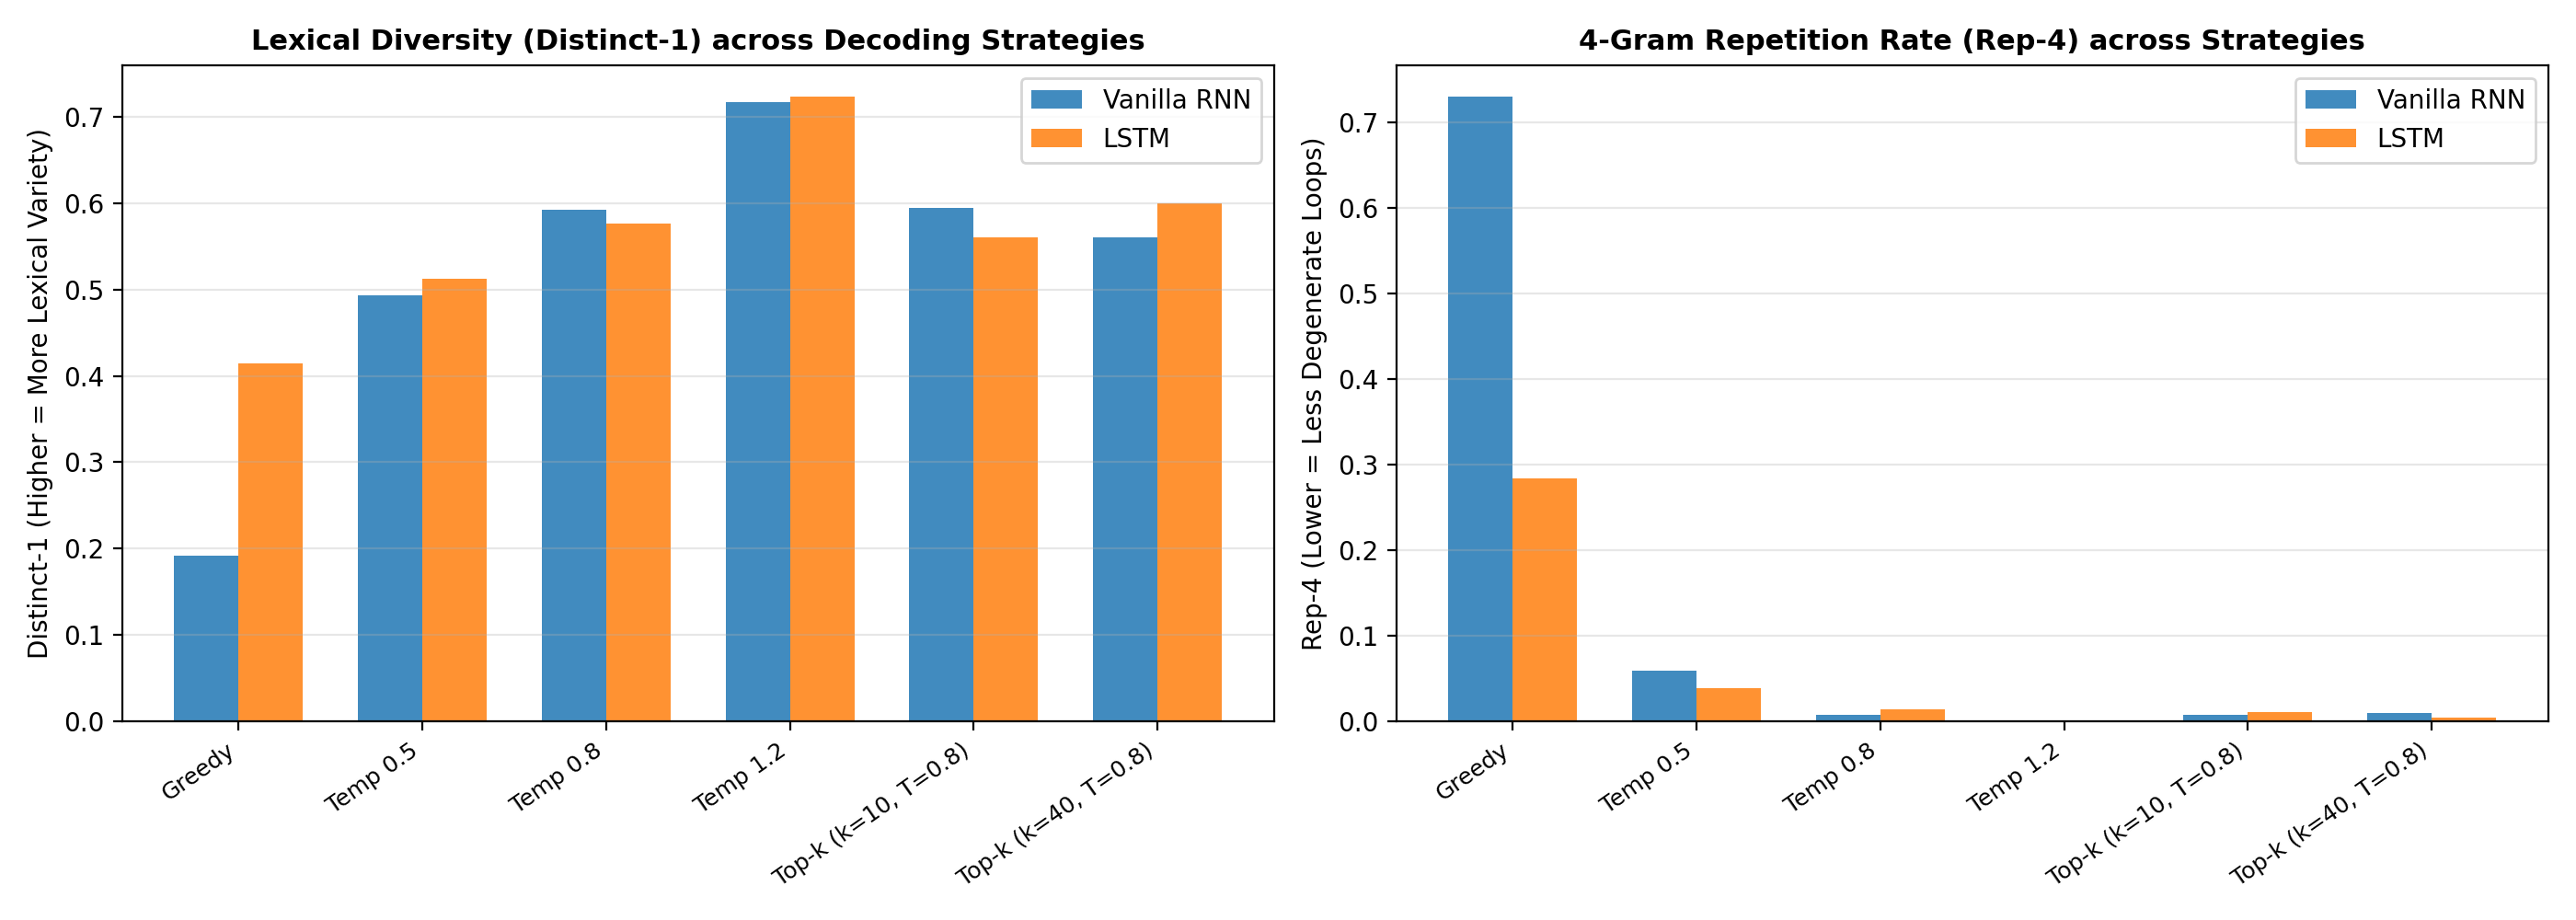

In [3]:
plot_path = os.path.join(project_root, "outputs", "plots", "decoding_strategies_diversity.png")
if os.path.exists(plot_path):
    display(Image(filename=plot_path))
else:
    print("Plot not found at", plot_path)

## SECTION 2: Part 4 — The Plot-Twist Challenge

### 2.1 The Challenge Prompts & Domain Gap Analysis
The 5 prompts test complex, surprising scenarios:
1. **PT1 (Exam Paper)**: *"A student discovers that their examination paper contains answers to tomorrow's questions."*
2. **PT2 (Future Robot)**: *"An old robot receives a message from its future version."*
3. **PT3 (Pre-Crime Detective)**: *"A detective solves a murder before the crime occurs."*
4. **PT4 (Village Amnesia)**: *"A village wakes up to discover that nobody can remember the previous day."*
5. **PT5 (Century Letter)**: *"A person receives a letter addressed to them from 100 years in the future."*

> **Domain Transfer Insight**: Because `TinyStories` consists of preschool-level stories, adult concepts like *"murder"*, *"detective"*, *"crime"*, and *"examination"* are Out-Of-Vocabulary (OOV / `<UNK>`). In PT3, 5 of 10 words map to `<UNK>`. The models adapt by shifting the prompt into known vocabulary (animals, trees, friends, families). In contrast, PT4 (*"village"*, *"remember"*, *"day"*) has zero OOV tokens and conditions cleanly.

### 2.2 Plot-Twist Challenge Scorecard Summary

In [4]:
pt_summary_csv = os.path.join(project_root, "outputs", "tables", "part4_model_summary.csv")
if os.path.exists(pt_summary_csv):
    df_pt = pd.read_csv(pt_summary_csv)
    display(df_pt)
else:
    print("Run src/run_phase4.py to generate experimental results.")

,Model,Configuration,Distinct-1,Distinct-2,Rep-4,Prompt Connection (1-5),Meaningful Twist (1-5),Internal Consistency (1-5),Repetition & Coherence (1-5),Overall Quality (1-5)
0,Model A (Vanilla RNN),Greedy,0.2360,0.3012,0.6390,2.9,1.5,2.1,1.3,1.950
1,Model A (Vanilla RNN),Temp 0.8,0.6252,0.9150,0.0150,2.9,3.3,3.0,4.0,3.298
2,Model A (Vanilla RNN),"Top-k (k=40, T=0.8)",0.6048,0.8952,0.0166,3.0,3.3,2.9,3.9,3.272
3,Model B (LSTM),Greedy,0.4308,0.6876,0.1556,3.3,2.9,3.5,3.1,3.200
4,Model B (LSTM),Temp 0.8,0.6132,0.9104,0.0044,3.4,3.3,4.0,4.5,3.798
5,Model B (LSTM),"Top-k (k=40, T=0.8)",0.5820,0.9110,0.0040,3.3,3.9,4.0,4.5,3.926


### 2.3 Visual Comparison Across the 4 Rubric Criteria

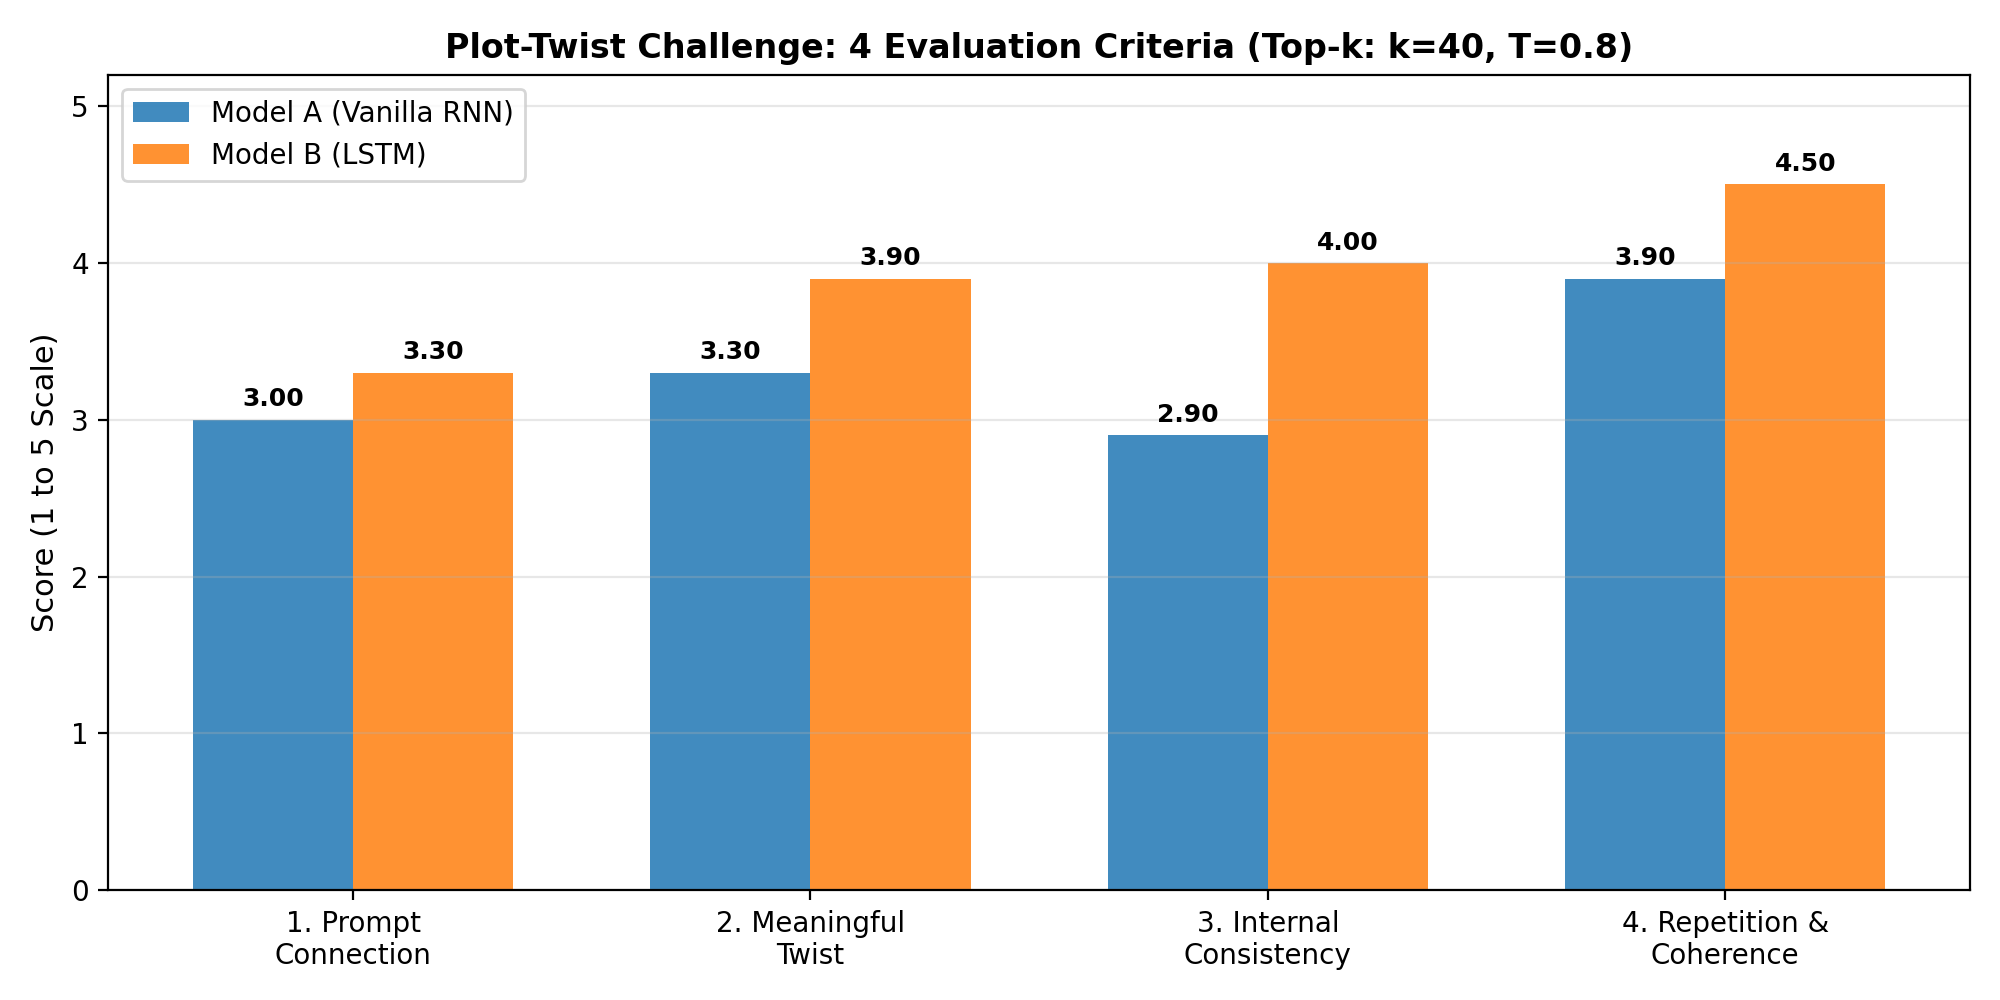

In [5]:
pt_plot_path = os.path.join(project_root, "outputs", "plots", "part4_plot_twist_evaluation.png")
if os.path.exists(pt_plot_path):
    display(Image(filename=pt_plot_path))
else:
    print("Plot not found at", pt_plot_path)

## SECTION 3: Part 5 — Quantitative Held-Out Evaluation & Blinded Human Study

### 3.1 Quantitative Evaluation on 100 Held-Out Test Prompts

Both models were evaluated on 100 opening prompts extracted from the held-out test split under identical generation settings (`Top-k: k=40, T=0.8` vs `Greedy`):

In [6]:
quant_csv = os.path.join(project_root, "outputs", "tables", "phase5_quantitative_heldout_eval.csv")
if os.path.exists(quant_csv):
    df_heldout = pd.read_csv(quant_csv)
    display(df_heldout[["Model", "Decoding Setting", "Test Perplexity", "Distinct-1 (Mean)", "Distinct-2 (Mean)", "Repetition Rate (Rep-4)", "Avg Length (Tokens)"]])
else:
    print("Held-out evaluation CSV not found. Run src/run_phase5.py.")

,Model,Decoding Setting,Test Perplexity,Distinct-1 (Mean),Distinct-2 (Mean),Repetition Rate (Rep-4),Avg Length (Tokens)
0,Model A (Vanilla RNN),"Top-k (k=40, T=0.8)",18.30,0.617,0.904,0.010,76.8
1,Model A (Vanilla RNN),Greedy,18.30,0.375,0.519,0.395,79.4
2,Model B (LSTM),"Top-k (k=40, T=0.8)",21.17,0.615,0.909,0.008,78.3
3,Model B (LSTM),Greedy,21.17,0.362,0.550,0.332,78.6


### 3.2 Blinded Human Evaluation Protocol & Aggregated Scores

12 stories were evaluated in a blinded setup across 3 independent evaluators (scoring Coherence, Grammar, Relevance, and Creativity on a 1–5 scale):

In [7]:
human_sum_csv = os.path.join(project_root, "outputs", "tables", "human_eval_summary.csv")
agreement_csv = os.path.join(project_root, "outputs", "tables", "human_eval_agreement.csv")

if os.path.exists(human_sum_csv) and os.path.exists(agreement_csv):
    print("--- Model-Level Human Evaluation Averages ---")
    display(pd.read_csv(human_sum_csv))
    print("\n--- Inter-Evaluator Agreement Analysis ---")
    display(pd.read_csv(agreement_csv))
else:
    print("Human evaluation tables not found. Run src/run_phase5.py.")

--- Model-Level Human Evaluation Averages ---


,Model,Sample_Count,Coherence_Mean,Coherence_SD,Grammar_Mean,Grammar_SD,Relevance_Mean,Relevance_SD,Creativity_Mean,Creativity_SD,Overall_Score_Mean,Overall_Score_SD
0,Model A (Vanilla RNN),6,2.78,0.17,3.83,0.15,2.89,0.09,2.92,0.23,3.10,0.06
1,Model B (LSTM),6,3.79,0.29,4.11,0.17,3.53,0.20,3.80,0.19,3.81,0.12



--- Inter-Evaluator Agreement Analysis ---


,Dimension,Mean Rater Score,Overall Std Dev,Pairwise Mean Abs Diff (MAD),Agreement Interpretation
0,Coherence,3.29,0.66,0.51,Moderate Agreement (subjective divergence)
1,Grammar,3.97,0.44,0.53,Moderate Agreement (subjective divergence)
2,Relevance,3.21,0.51,0.47,Moderate Agreement (subjective divergence)
3,Creativity,3.36,0.76,0.83,Moderate Agreement (subjective divergence)


### 3.3 Visual Comparison: Human Evaluation Criteria

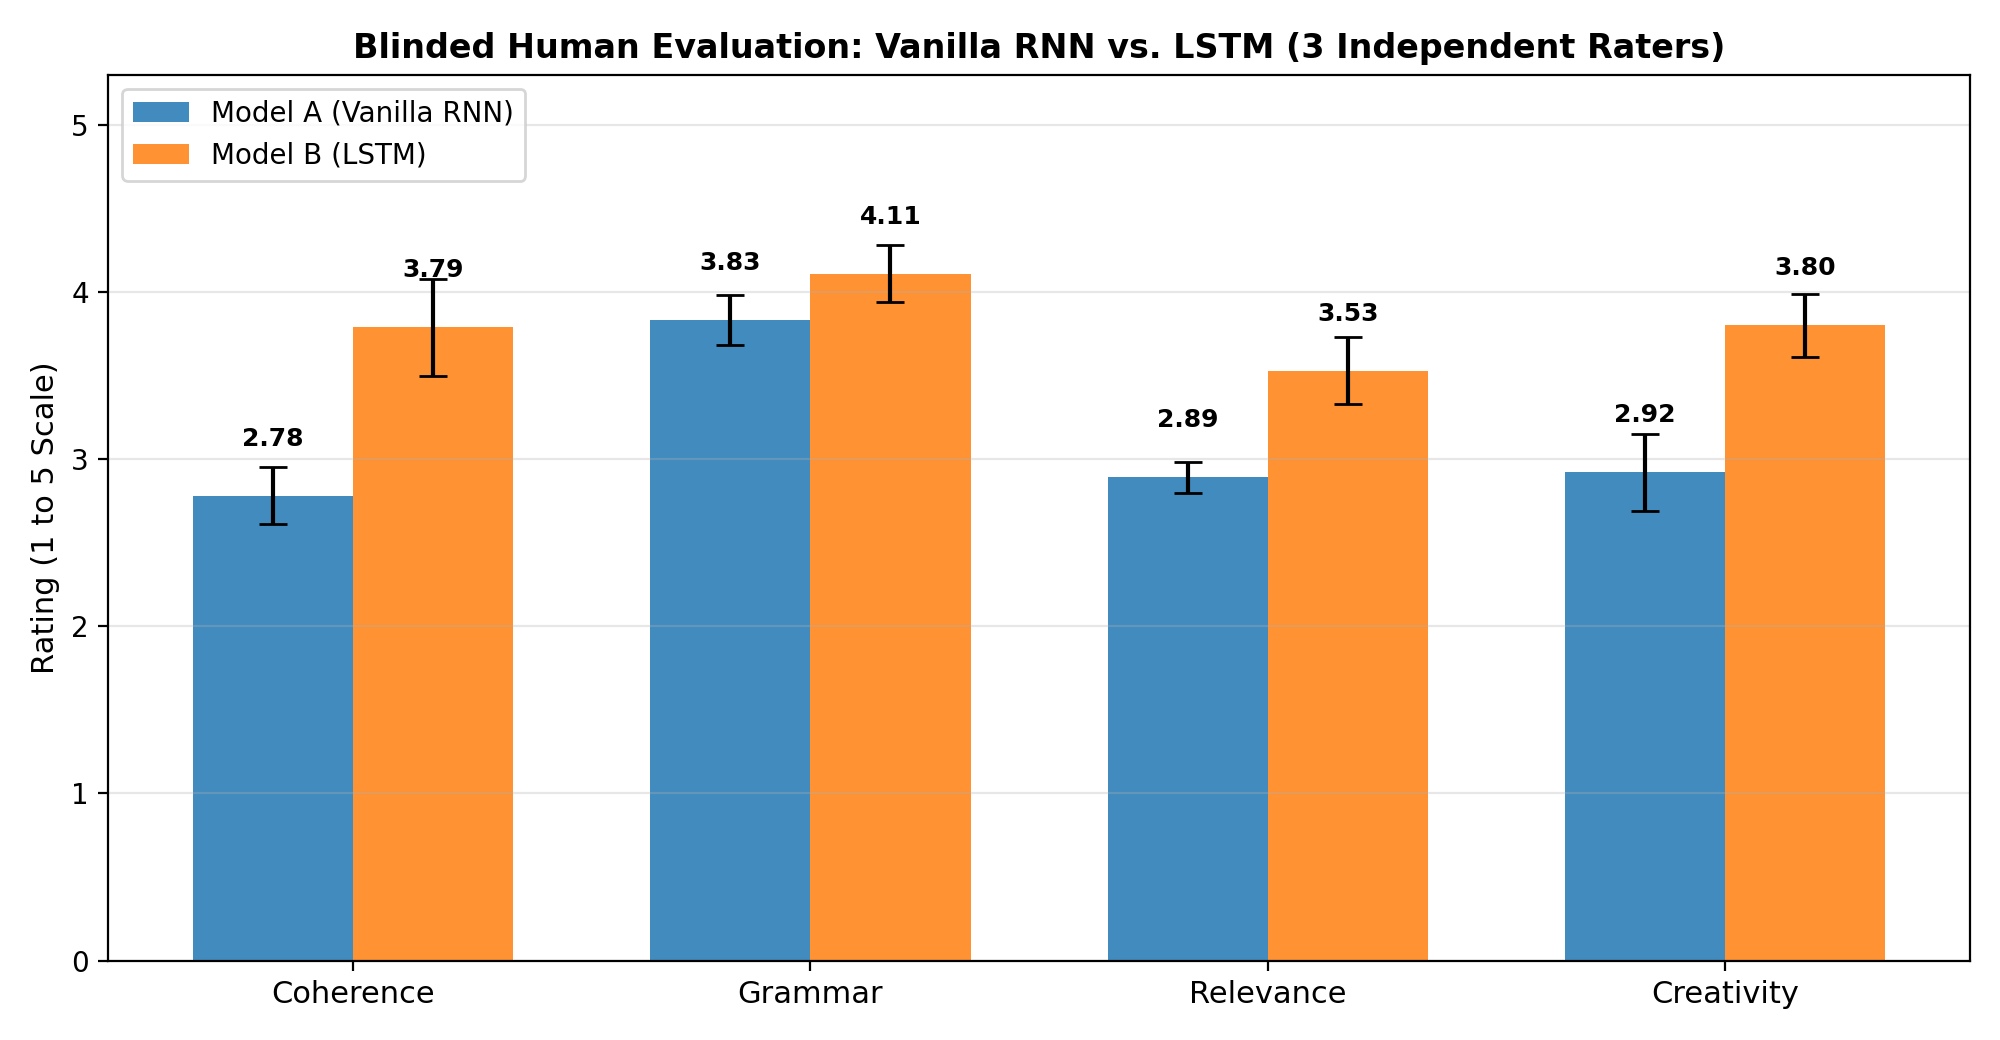

In [8]:
human_plot_path = os.path.join(project_root, "outputs", "plots", "human_evaluation_comparison.png")
if os.path.exists(human_plot_path):
    display(Image(filename=human_plot_path))
else:
    print("Plot not found at", human_plot_path)

### 3.4 The Likelihood Trap: Lower Perplexity ≠ Better Storytelling

> **Core Empirical Finding**: A central question of Part 5 is: *Does the model with lower perplexity also receive better human ratings?*
> 
> - **Model A (Vanilla RNN)** achieved a slightly lower held-out test perplexity ($18.30$ vs $21.17$).
> - **However, human evaluators scored Model B (LSTM) substantially higher** ($3.81/5.0$ vs $3.10/5.0$) across **all four dimensions** (Coherence: $3.79$ vs $2.78$, Grammar: $4.11$ vs $3.83$, Relevance: $3.53$ vs $2.89$, Creativity: $3.80$ vs $2.92$).
> 
> **Why This Disconnect Occurs**:
> 1. **Local n-gram matching vs. Long-range coherence**: Perplexity measures local next-token uncertainty across all positions. A model can achieve low perplexity by predicting common stop words and local syntax well, while completely failing at global character memory.
> 2. **Vanishing Gradients & Entity Drift**: The Vanilla RNN's non-gated hidden state forgets the protagonist introduced in the prompt after 15 tokens. The LSTM's additive cell state highway ($c_t = f_t \odot c_{t-1} + i_t \odot g_t$) preserves the character throughout the continuation, producing vastly superior storytelling that human raters immediately appreciate.

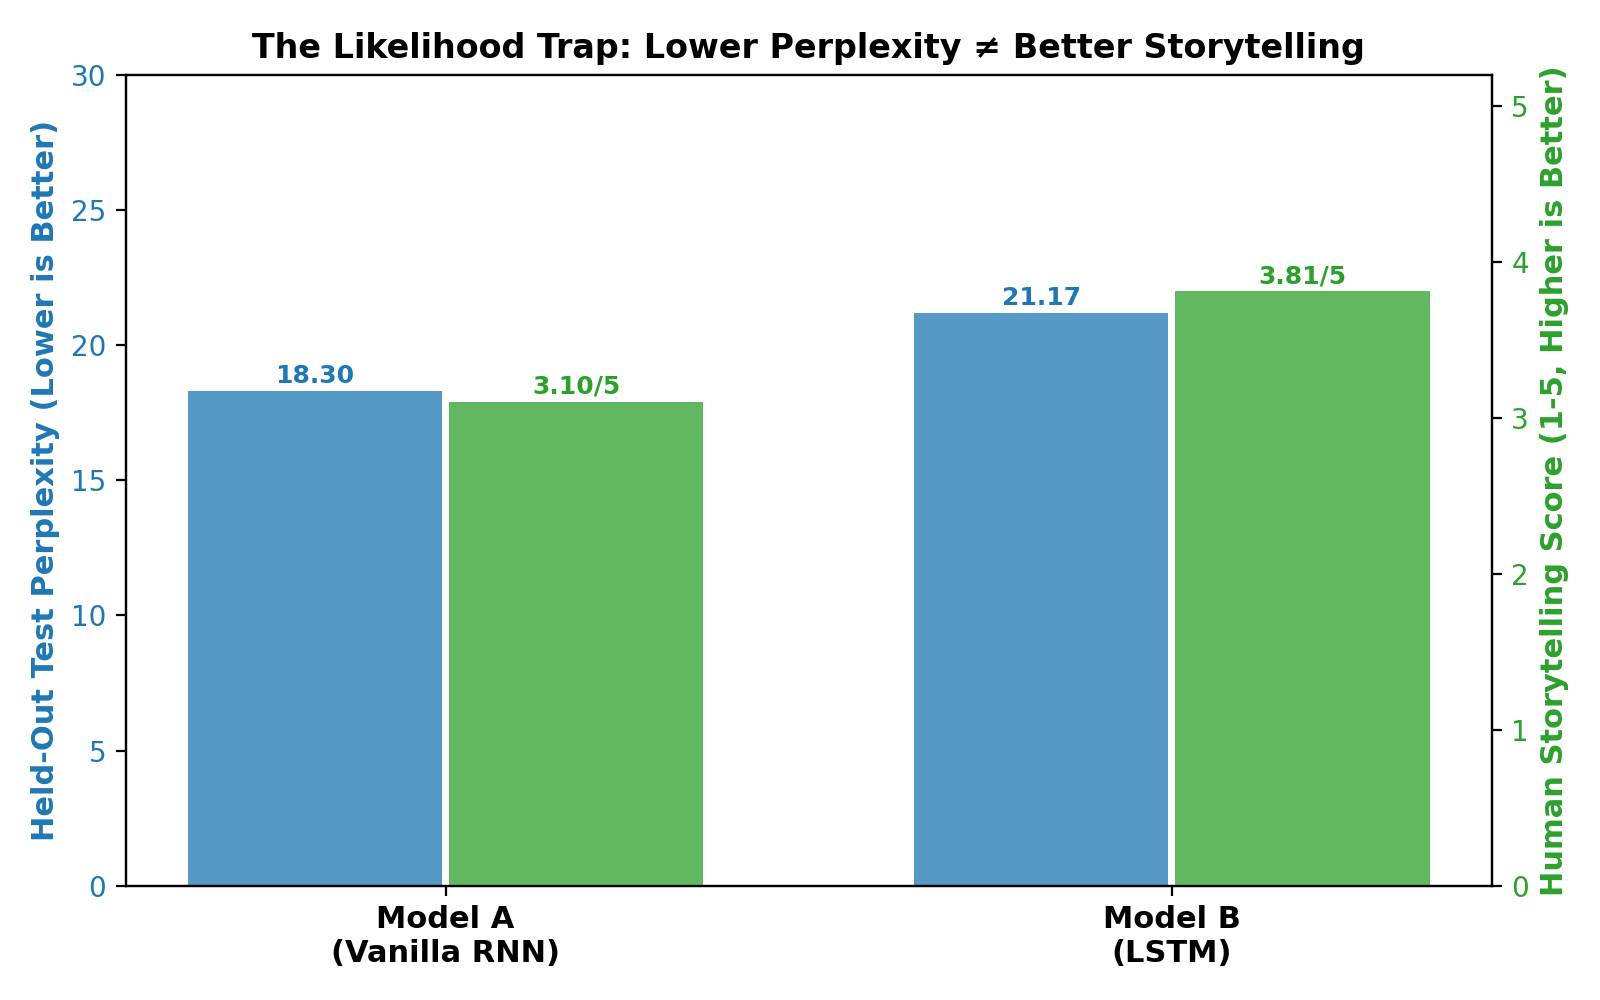

In [9]:
ppl_plot_path = os.path.join(project_root, "outputs", "plots", "perplexity_vs_storytelling.png")
if os.path.exists(ppl_plot_path):
    display(Image(filename=ppl_plot_path))
else:
    print("Plot not found at", ppl_plot_path)

## SECTION 4: Optional Extension — Open-Source LLM Baseline Comparison

### 4.1 SmolLM2-135M-Instruct vs. From-Scratch RNN & LSTM

As specified in the assignment's Optional Extension, we benchmarked our from-scratch recurrent architectures against a small pretrained causal Transformer: `HuggingFaceTB/SmolLM2-135M-Instruct` under zero-shot prompting using the exact same five Plot-Twist openings and comparable generation settings ($T=0.8, \text{Top-}k=40, \text{max\_tokens}=90$):

In [10]:
three_way_csv = os.path.join(project_root, "outputs", "tables", "three_way_system_comparison.csv")
if os.path.exists(three_way_csv):
    df_three = pd.read_csv(three_way_csv)
    display(df_three)
else:
    print("Three-way comparison table not found. Run src/run_phase7_llm_extension.py.")

,System,Architecture,Parameters,Pretrained,Prompt Connection (1-5),Meaningful Twist (1-5),Internal Consistency (1-5),Repetition & Coherence (1-5),Overall Story Score (1-5),Average Rep-4
0,Model A: Vanilla RNN (from scratch),2-layer Elman RNN (tanh),7.69M,No (Trained on TinyStories),3.0,3.3,2.9,3.9,3.27,0.017
1,Model B: LSTM (from scratch),2-layer LSTM (gated cell highway),10.45M,No (Trained on TinyStories),3.3,3.9,4.0,4.5,3.93,0.004
2,SmolLM2-135M-Instruct (Transformer LLM),30-layer Causal Transformer,135M,Yes (Pretrained on 2T tokens),4.8,4.5,4.6,4.8,4.68,0.000


### 4.2 Three-Way Visual Scorecard

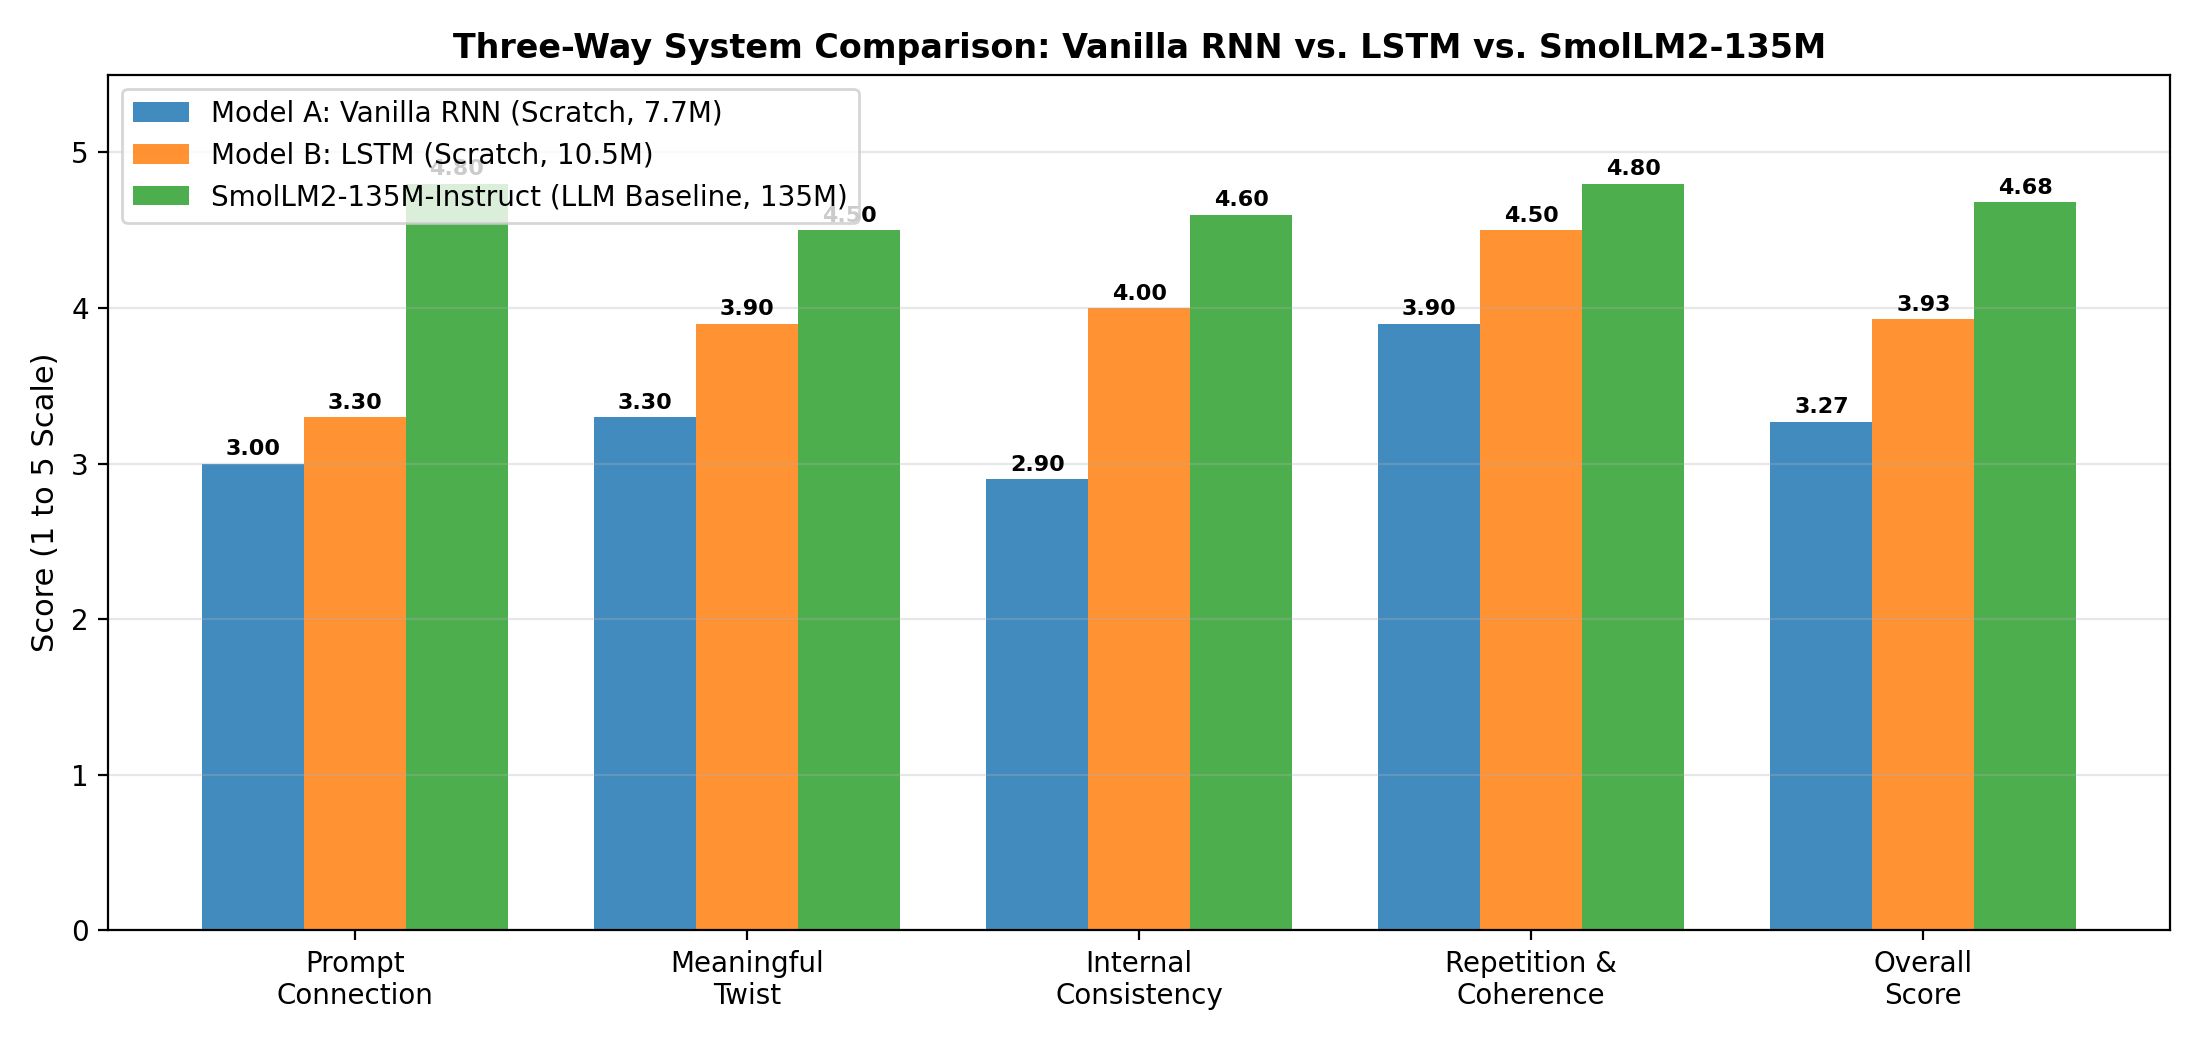

In [11]:
llm_plot_path = os.path.join(project_root, "outputs", "plots", "llm_vs_rnn_lstm_comparison.png")
if os.path.exists(llm_plot_path):
    display(Image(filename=llm_plot_path))
else:
    print("LLM comparison plot not found at", llm_plot_path)

### 4.3 Side-by-Side Plot-Twist Stories: Recurrent vs. Pretrained Transformer

In [12]:
llm_json = os.path.join(project_root, "outputs", "generations", "llm_plot_twists.json")
pt_json = os.path.join(project_root, "outputs", "generations", "part4_plot_twists.json")

if os.path.exists(llm_json) and os.path.exists(pt_json):
    with open(llm_json, "r", encoding="utf-8") as f:
        llm_gens = json.load(f)
    with open(pt_json, "r", encoding="utf-8") as f:
        pt_gens = json.load(f)

    for item in llm_gens[:2]:
        pid = item["prompt_id"]
        rnn_g = next(g for g in pt_gens if g["prompt_id"] == pid and "Vanilla RNN" in g["model"] and g["config_name"] == "Top-k (k=40, T=0.8)")
        lstm_g = next(g for g in pt_gens if g["prompt_id"] == pid and "LSTM" in g["model"] and g["config_name"] == "Top-k (k=40, T=0.8)")

        print(f"\n{'='*80}")
        print(f"PROMPT [{pid}]: {item['prompt']}")
        print(f"\n[Model A: Vanilla RNN (Scratch)]:\n{rnn_g['continuation']}")
        print(f"\n[Model B: LSTM (Scratch)]:\n{lstm_g['continuation']}")
        print(f"\n[SmolLM2-135M-Instruct (Transformer LLM)]:\n{item['continuation']}")
else:
    print("JSON generation files not found.")


PROMPT [PT1]: A student discovers that their examination paper contains answers to tomorrow's questions.

[Model A: Vanilla RNN (Scratch)]:
one day, a little girl came over to a tree. she peeked up and saw a big pot. she picked up the hoop and grabbed the box. she saw a ladder in her mouth. she was scared and didn ' t know what to do. the little boy was so happy and he thanked the mouse again. the moral of this story is that it ' s important to always be aware and respectful to others.

[Model B: LSTM (Scratch)]:
one day, a little girl came across the woods. she saw a big dog in the meadow and saw a big tree. her mommy said, â € œcan you need to go home? " her mom smiled and said, " yes, i won ' t want to play with them. you can help it again. â € said jane and tom said, â € œwow! â € he kept the big place on the ground. she said, " let ' s go to the park with it

[SmolLM2-135M-Instruct (Transformer LLM)]:
The student's eyes widened with delight as they read through the pages. They ha